In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-optimization", "numpy", "scipy", "torch", "matplotlib"]:
    print(name, version(name))
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
print("설치 및 import 확인 완료")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.18
qiskit 2.2.3
qiskit-optimization 0.7.0
numpy 2.1.3
scipy 1.16.3
torch 2.11.0+cpu
matplotlib 3.10.0
설치 및 import 확인 완료


[Epoch100] Val MSE:0.0108 WithinTol:94.52%
[Epoch200] Val MSE:0.0085 WithinTol:97.24%
[Epoch300] Val MSE:0.0049 WithinTol:99.24%
[Epoch400] Val MSE:0.0056 WithinTol:98.68%
[Epoch500] Val MSE:0.0047 WithinTol:99.32%


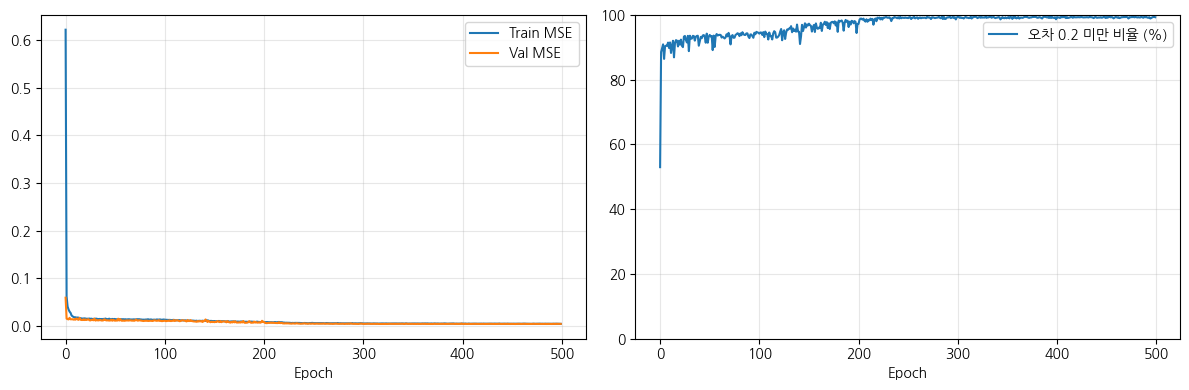

정확한 최솟값=1084.589844, QAOA 후보 비용=1084.589844, 차이=0.000000
유효 후보 관측 비율=0.1953, 최적 후보 관측 비율=0.0022

QAOA 기반 식품회사 원부자재 최적 매입 결과
선택된 공급업체: A_안성
예측 리스크: 1.45
총 비용: 1084.59
QAOA 최소비용값(fval): 1084.59


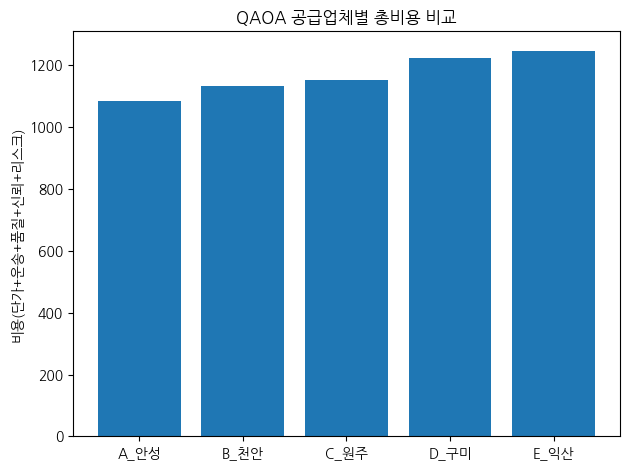

검증 MSE=0.004719, RMSE=0.068695, MAE=0.053558


In [9]:
from itertools import product
import numpy as np
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

def solve_checked(problem, reps=2, maxiter=100, seed=42):
    # 원문제의 제약을 유지한 채 내부 QUBO 변환과 역변환을 맡깁니다.
    qaoa = QAOA(
        sampler=StatevectorSampler(default_shots=4096, seed=seed),
        optimizer=COBYLA(maxiter=maxiter), reps=reps,
        initial_point=np.random.default_rng(seed).uniform(0.1, 1.0, 2*reps),
    )
    result = MinimumEigenOptimizer(qaoa).solve(problem)
    if result.x is None or not problem.is_feasible(result.x):
        raise RuntimeError("유효한 선택을 얻지 못했습니다. 샷·초깃값·탐색 예산을 바꿔 재실행하세요.")
    assert np.isclose(np.sum(result.x), 1)
    assert np.all(np.isclose(result.x, 0) | np.isclose(result.x, 1))
    assert np.isclose(result.fval, problem.objective.evaluate(result.x))
    feasible = [np.array(x) for x in product([0,1], repeat=problem.get_num_vars())
                if problem.is_feasible(np.array(x))]
    exact = min(float(problem.objective.evaluate(x)) for x in feasible)
    valid_mass = sum(float(s.probability) for s in result.samples if problem.is_feasible(s.x))
    best_mass = sum(float(s.probability) for s in result.samples
                    if problem.is_feasible(s.x) and np.isclose(s.fval, exact))
    gap = float(result.fval-exact)
    assert gap >= -1e-6 and np.isfinite(result.fval)
    assert np.isclose(sum(float(s.probability) for s in result.samples),1)
    print(f"정확한 최솟값={exact:.6f}, QAOA 후보 비용={result.fval:.6f}, 차이={gap:.6f}")
    print(f"유효 후보 관측 비율={valid_mass:.4f}, 최적 후보 관측 비율={best_mass:.4f}")
    return result

# ============================================
# QAOA 응용 5 - 식품회사 원부자재 매입비용 최적화
# ============================================

import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# -------------------------------------------
# 기본 설정
# -------------------------------------------
suppliers = ["A_안성", "B_천안", "C_원주", "D_구미", "E_익산"]
unit_price = {"A_안성":820,"B_천안":780,"C_원주":740,"D_구미":720,"E_익산":700}
transport = {"A_안성":70,"B_천안":90,"C_원주":120,"D_구미":150,"E_익산":180}
quality = {"A_안성":4,"B_천안":3,"C_원주":3,"D_구미":2,"E_익산":2}
reliab = {"A_안성":95,"B_천안":90,"C_원주":85,"D_구미":80,"E_익산":75}

quantity_kg = 1.0  # 단위 검증을 위한 수업용 구매량
alpha1, alpha2 = 40.0, 2.0
rng=np.random.default_rng(42)
torch.manual_seed(42)
torch.set_num_threads(1)

# -------------------------------------------
# 합성 리스크 데이터 생성
# -------------------------------------------
def simulate_risk(price_var, oil, fx, demand):
    risk = np.array([0.8,1.0,1.2,1.3,1.4],dtype=float)
    if price_var>0.5: risk+=0.3
    if oil>0.6: risk+=0.2
    if fx>0.5: risk+=0.2
    if demand>0.6: risk+=0.1
    risk+=rng.normal(0,0.05,5)
    return np.clip(risk,0.5,2.0)

N=2500
X=np.zeros((N,4));Y=np.zeros((N,5))
for i in range(N):
    price_var, oil, fx, demand=rng.random(4)
    X[i]=[price_var,oil,fx,demand]
    Y[i]=simulate_risk(price_var,oil,fx,demand)

idx=np.arange(N);rng.shuffle(idx);cut=int(0.8*N)
Xtr,Ytr,Xva,Yva=X[idx[:cut]],Y[idx[:cut]],X[idx[cut:]],Y[idx[cut:]]

# -------------------------------------------
# PyTorch MLP
# -------------------------------------------
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(4,32),nn.ReLU(),nn.Dropout(0.2),
            nn.Linear(32,16),nn.ReLU(),
            nn.Linear(16,5)
        )
    def forward(self,x): return self.net(x)

device=torch.device("cpu")
model=MLP().to(device)
criterion=nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)
scheduler=StepLR(optimizer,step_size=100,gamma=0.5)

train_loader=DataLoader(TensorDataset(torch.tensor(Xtr,dtype=torch.float32),
                                     torch.tensor(Ytr,dtype=torch.float32)),batch_size=64,shuffle=True)
val_loader=DataLoader(TensorDataset(torch.tensor(Xva,dtype=torch.float32),
                                   torch.tensor(Yva,dtype=torch.float32)),batch_size=256)

# -------------------------------------------
# 학습 루프
# -------------------------------------------
epochs=500
tr_mse,va_mse,va_acc=[],[],[]

def within_tolerance(y_true,y_pred,tol=0.2):
    diff=torch.abs(y_true-y_pred)
    within=(diff<tol).float().mean().item()
    return within*100

for ep in range(1,epochs+1):
    model.train();loss_sum=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        pred=model(xb);loss=criterion(pred,yb)
        optimizer.zero_grad();loss.backward();optimizer.step()
        loss_sum+=loss.item()*xb.size(0)
    scheduler.step()
    tr_mse.append(loss_sum/len(train_loader.dataset))
    model.eval();v_loss,v_acc=0,0
    with torch.no_grad():
        for xb,yb in val_loader:
            xb,yb=xb.to(device),yb.to(device)
            pred=model(xb)
            v_loss+=criterion(pred,yb).item()*xb.size(0)
            v_acc+=within_tolerance(yb,pred)*xb.size(0)
    va_mse.append(v_loss/len(val_loader.dataset))
    va_acc.append(v_acc/len(val_loader.dataset))
    if ep%100==0: print(f"[Epoch{ep:3d}] Val MSE:{va_mse[-1]:.4f} WithinTol:{va_acc[-1]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(tr_mse,label="Train MSE"); axes[0].plot(va_mse,label="Val MSE")
axes[1].plot(va_acc,label="오차 0.2 미만 비율 (%)"); axes[1].set_ylim(0,100)
for ax in axes: ax.legend(); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("training_performance_qaoa5.png")
plt.show(); plt.close()

# -------------------------------------------
# QAOA 비용 계산
# -------------------------------------------
current=np.array([[0.7,0.8,0.6,0.5]])  # 원가상승, 유가상승, 환율높음, 수요보통
with torch.no_grad():
    pred_risk=model(torch.tensor(current,dtype=torch.float32,device=device)).cpu().numpy().flatten()
pred_risk=np.clip(pred_risk,0.5,2.0)

costs={s:(quantity_kg*unit_price[s]+transport[s]+alpha1*(5-quality[s])+alpha2*(100-reliab[s])+100*pred_risk[i])
       for i,s in enumerate(suppliers)}

qaoa_reps, qaoa_maxiter = 3, 200

problem=QuadraticProgram()
for s in suppliers: problem.binary_var(s)
problem.linear_constraint({s:1 for s in suppliers},"==",1)
problem.minimize(linear=costs)
result = solve_checked(problem, reps=qaoa_reps, maxiter=qaoa_maxiter)

selected=[s for s,v in zip(suppliers,result.x) if v==1][0]
print("\n============================================")
print("QAOA 기반 식품회사 원부자재 최적 매입 결과")
print("============================================")
print("선택된 공급업체:",selected)
print("예측 리스크:",round(pred_risk[suppliers.index(selected)],2))
print("총 비용:",round(costs[selected],2))
print("QAOA 최소비용값(fval):",round(result.fval,2))
print("============================================")

plt.figure()
plt.bar(suppliers,[costs[s] for s in suppliers])
plt.title("QAOA 공급업체별 총비용 비교")
plt.ylabel("비용(단가+운송+품질+신뢰+리스크)")
plt.tight_layout();plt.savefig("qaoa_supplier_result.png")
plt.show(); plt.close()


assert np.isfinite(tr_mse).all() and np.isfinite(va_mse).all()
assert tr_mse[-1] < tr_mse[0]
model.eval()
with torch.no_grad():
    check_pred = model(torch.tensor(Xva,dtype=torch.float32,device=device)).cpu().numpy()
assert check_pred.shape == Yva.shape and np.isfinite(check_pred).all()
rmse = float(np.sqrt(np.mean((check_pred-Yva)**2)))
mae = float(np.mean(np.abs(check_pred-Yva)))
print(f"검증 MSE={np.mean((check_pred-Yva)**2):.6f}, RMSE={rmse:.6f}, MAE={mae:.6f}")